In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"])

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'open_clip_torch'], returncode=0)

In [2]:
import os, json, random, tarfile, copy
from collections import defaultdict, Counter
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download
import open_clip
 
assert torch.cuda.is_available(), "Pas de GPU : Session options > Accelerator > GPU T4"
dev = "cuda"
random.seed(0); np.random.seed(0); torch.manual_seed(0)
login(UserSecretsClient().get_secret("hf_syrine"))
 
REPO = "ArtmeScienceLab/Garments2Look"
SHARDS = [17, 16]                   # [NOUVEAU - point 6] 2 archives = plus de tenues (17 = la plus legere, 2.3 Go)
OUT = "/kaggle/working/g2l_images"
os.makedirs(OUT, exist_ok=True)

In [3]:
avail = set()
for shard in SHARDS:
    tar_path = hf_hub_download(REPO, f"mytheresa/images-{shard:05d}.tar.gz",
                               repo_type="dataset", local_dir="/kaggle/working/g2l_dl")
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar:
            parts = m.name.split("/")
            if m.isfile() and len(parts) == 4 and parts[3] == parts[2] + ".jpg":
                im = Image.open(tar.extractfile(m)).convert("RGB")
                im.thumbnail((448, 448)); im.save(f"{OUT}/{parts[2]}.jpg", quality=90)
                avail.add(parts[2])
    os.remove(tar_path)
print(len(avail), "articles avec photo")

mytheresa/images-00017.tar.gz: reconstructing file:   0%|          |  0.00B / 2.34GB            

mytheresa/images-00017.tar.gz: downloading bytes:           |  0.00B            

mytheresa/images-00016.tar.gz: reconstructing file:   0%|          |  0.00B / 10.4GB            

mytheresa/images-00016.tar.gz: downloading bytes:           |  0.00B            

4386 articles avec photo


In [4]:
data = json.load(open(hf_hub_download(REPO, "mytheresa_outfit_v1.0_2512.json", repo_type="dataset")))
 
CATS = [("shoes", ["sneaker", "boot", "sandal", "loafer", "pump", "heel", "flat", "mule", "shoe",
                   "slipper", "slide", "oxford", "derby", "espadrille", "trainer"]),
        ("bag", ["bag", "tote", "clutch", "backpack", "purse", "pouch"]),
        ("dress", ["dress", "gown", "jumpsuit", "playsuit"]),
        ("outer", ["coat", "jacket", "blazer", "parka", "trench", "vest", "gilet", "cape", "poncho"]),
        ("top", ["t-shirt", "shirt", "blouse", "sweater", "top", "knit", "cardigan", "hoodie",
                 "sweatshirt", "polo", "tank", "bodysuit", "jumper", "turtleneck", "tee"]),
        ("bottom", ["pant", "trouser", "jean", "skirt", "short", "legging", "jogger"])]
 
def category(desc):
    d = desc.lower()
    for cat, keys in CATS:
        if any(k in d for k in keys):
            return cat
    return "other"
 
desc_of, raw_outfits = {}, []
for oid, o in data.items():
    for c, d in o["outfit"].items():
        desc_of.setdefault(c, d)
    if o["is_official_outfit"] and o["is_official_look"]:
        codes = [c for c in o["outfit"] if c in avail]
        # [MODIF] Tenues de 3 à 5 items
        if 3 <= len(codes) <= 5:
            info = o["outfit_info"]
            raw_outfits.append(dict(
                codes=codes[:5],                       # [MODIF] max 5 items
                season=info.get("season", "") or "unknown",
                style=info.get("style", "") or "other",
                colors=info.get("color_palette", []),
                complete=len(codes) == len(o["outfit"]) and len(codes) <= 5  # [MODIF] <= 5
            ))
print(len(raw_outfits), "tenues officielles de 3 à 5 items avec photos")
assert len(raw_outfits) >= 80, "Trop peu de tenues : ajoute une archive dans SHARDS (ex : [17, 16])"
 
used = sorted({c for of in raw_outfits for c in of["codes"]})
code2idx = {c: i for i, c in enumerate(used)}
DESC = [desc_of[c] for c in used]
CAT = [category(d) for d in DESC]
for of in raw_outfits:
    of["items"] = [code2idx[c] for c in of["codes"]]
 
random.shuffle(raw_outfits)
n_tr = int(0.8 * len(raw_outfits))
trainval = raw_outfits[:n_tr]
train_items = {i for of in trainval for i in of["items"]}
pool_test = [of for of in raw_outfits[n_tr:] if not (set(of["items"]) & train_items)]
if len(pool_test) < 10:
    print("ATTENTION : test pas totalement disjoint du train (peu de donnees)")
    pool_test = raw_outfits[n_tr:]
n_val = max(8, len(trainval) // 10)
pool_val, pool_train = trainval[:n_val], trainval[n_val:]
test_items = {i for of in pool_test for i in of["items"]}
print(f"{len(used)} articles | train {len(pool_train)} tenues | val {len(pool_val)} | test {len(pool_test)} "
      f"({len(test_items)} articles jamais vus)")
print("Categories :", {c: CAT.count(c) for c in sorted(set(CAT))})
print("tenues COMPLETES (aucun article perdu) :", sum(of["complete"] for of in raw_outfits), "/", len(raw_outfits))

mytheresa_outfit_v1.0_2512.json: reconstructing file:   0%|          |  0.00B /  102MB            

mytheresa_outfit_v1.0_2512.json: downloading bytes:           |  0.00B            

456 tenues officielles de 3 à 5 items avec photos
ATTENTION : test pas totalement disjoint du train (peu de donnees)
643 articles | train 328 tenues | val 36 | test 92 (259 articles jamais vus)
Categories : {'bag': 55, 'bottom': 140, 'dress': 24, 'other': 43, 'outer': 103, 'shoes': 106, 'top': 172}
tenues COMPLETES (aucun article perdu) : 94 / 456


In [5]:
# %% Cellule 3b : [NOUVEAU - point 4] tokens de contexte : style, saison, couleurs
def vocab(values, max_size=None):                       # 0 = "inconnu"
    return {v: i + 1 for i, (v, _) in enumerate(Counter(values).most_common(max_size))}

def low(x):
    return str(x).lower().strip()

def pal_names(colors):
    if not colors:
        return []
    return [low(c) for c in (colors if isinstance(colors, (list, tuple)) else [colors])]

# vocabulaires construits sur le TRAIN uniquement (ce qui est inconnu -> token "inconnu")
STY = vocab([low(of["style"]) for of in pool_train])
SEA = vocab([low(of["season"]) for of in pool_train])
COLV = vocab([c for of in pool_train for c in pal_names(of["colors"])], 24)

def meta_ids(style="", season="", colors=()):
    """(style, saison, couleur1, couleur2) -> indices de vocabulaire (0 = inconnu)."""
    cs = [COLV.get(c, 0) for c in pal_names(colors)][:2]
    cs += [0] * (2 - len(cs))
    return (STY.get(low(style), 0), SEA.get(low(season), 0), cs[0], cs[1])

for of in raw_outfits:
    of["meta"] = meta_ids(of["style"], of["season"], of["colors"])
print(f"styles : {len(STY)} | saisons : {len(SEA)} | couleurs : {len(COLV)}")
print("exemple de meta :", raw_outfits[0]["style"], raw_outfits[0]["season"], raw_outfits[0]["colors"][:2], "->", raw_outfits[0]["meta"])

styles : 112 | saisons : 21 | couleurs : 24
exemple de meta : Contemporary Casual Autumn ['Olive Green', 'Dark Brown'] -> (5, 1, 17, 7)


/tmp/ipykernel_49/3719715742.py:10: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout(); plt.show()


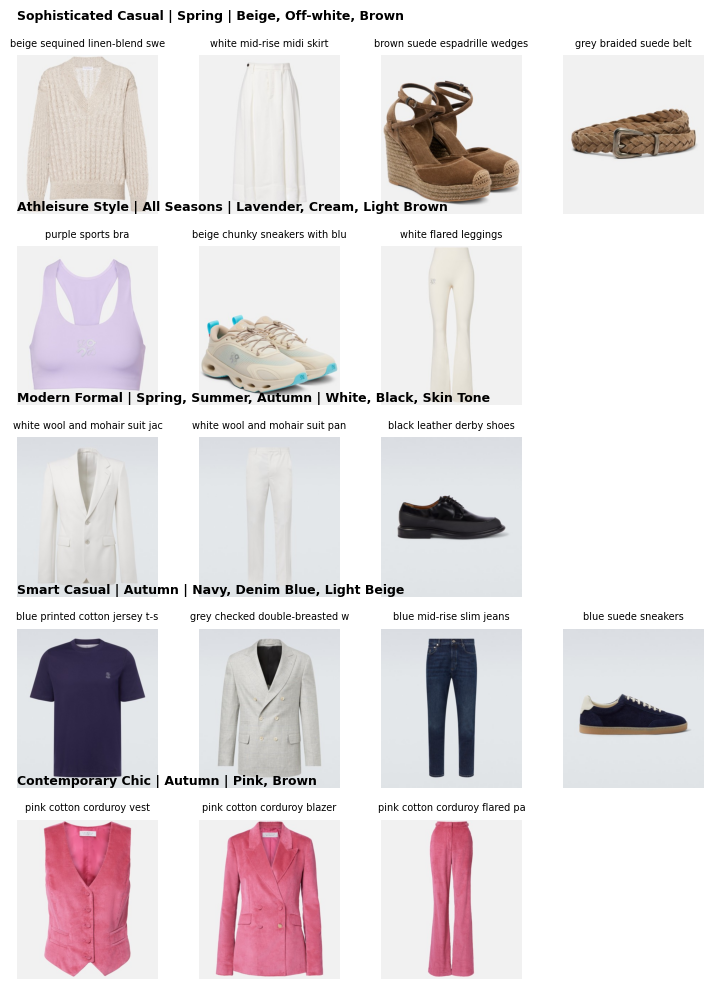

In [6]:
fig, axs = plt.subplots(5, 4, figsize=(9, 12))
for r, of in enumerate(random.sample(raw_outfits, 5)):
    for c in range(4):
        ax = axs[r][c]; ax.axis("off")
        if c < len(of["items"]):
            ax.imshow(Image.open(f"{OUT}/{of['codes'][c]}.jpg"))
            ax.set_title(DESC[of["items"][c]][:30], fontsize=7)
    axs[r][0].text(0, 1.22, f"{of['style']} | {of['season']} | {', '.join(of['colors'][:3])}",
                   transform=axs[r][0].transAxes, fontsize=9, weight="bold")
plt.tight_layout(); plt.show()

In [7]:
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
clip_model = clip_model.to(dev).eval()
embs = []
with torch.no_grad():
    for i in range(0, len(used), 128):
        x = torch.stack([preprocess(Image.open(f"{OUT}/{c}.jpg").convert("RGB")) for c in used[i:i + 128]]).to(dev)
        embs.append(F.normalize(clip_model.encode_image(x).float(), dim=-1).cpu())
emb = torch.cat(embs)

print("vecteurs CLIP :", tuple(emb.shape))
# [NOUVEAU - point 7] couleur de chaque article, devinee par CLIP (zero-shot) : sert au re-ranking final
COLORS = ["black", "white", "beige", "brown", "grey", "navy", "blue", "green", "red", "pink",
          "yellow", "orange", "purple", "gold", "silver", "cream"]
tokenizer = open_clip.get_tokenizer("ViT-B-32")
with torch.no_grad():
    txt = F.normalize(clip_model.encode_text(tokenizer([f"a photo of a {c} fashion item" for c in COLORS]).to(dev)).float(), dim=-1).cpu()
COLP = F.softmax(100 * emb @ txt.T, dim=-1).numpy().astype(np.float32)     # (n_articles, n_couleurs)
print("couleur dominante, 5 articles :", [COLORS[j] for j in COLP[:5].argmax(1)])
del clip_model; torch.cuda.empty_cache()

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

vecteurs CLIP : (643, 512)
couleur dominante, 5 articles : ['grey', 'brown', 'red', 'white', 'red']


RQ-VAE epoque 1/300  loss 2.173
RQ-VAE epoque 101/300  loss 1.645
RQ-VAE epoque 201/300  loss 1.656
RQ-VAE epoque 300/300  loss 1.656
erreur de reconstruction : articles vus 0.40 | articles jamais vus 0.52   (1.00 = ne reconstruit rien)
adresses differentes (3 premiers niveaux) : 595 / 643
exemples de semantic IDs : [(49, 62, 44, 0), (48, 25, 34, 0), (31, 25, 16, 0), (31, 6, 62, 0)]


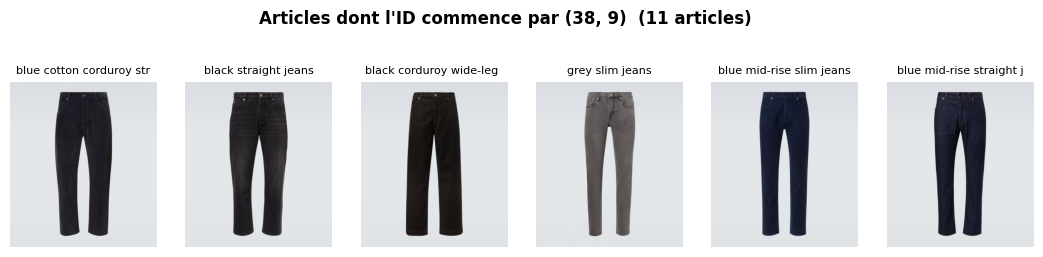

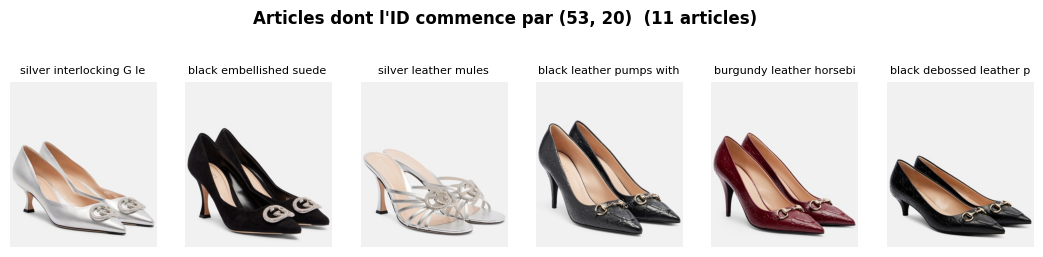

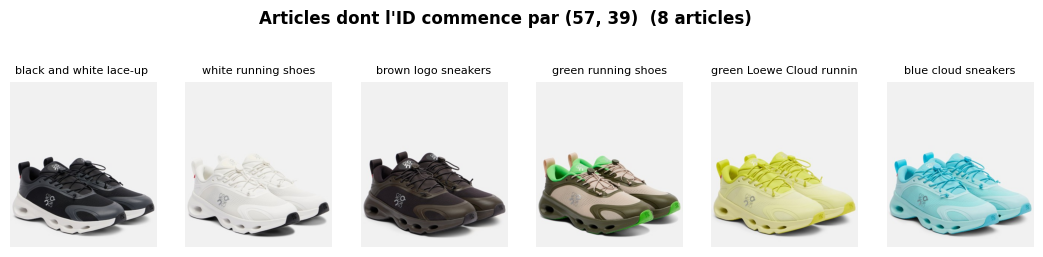

In [8]:
KC, LV = 64, 3          # 64 reperes par niveau, 3 niveaux
L = LV + 1              # tokens par article
 
def kmeans(x, k, iters=15):
    c = x[torch.randperm(len(x))[:k]].clone()
    for _ in range(iters):
        a = torch.cdist(x, c).argmin(1)
        for j in range(k):
            if (a == j).any():
                c[j] = x[a == j].mean(0)
    return c
 
class RQVAE(nn.Module):
    def __init__(self, d_in=512, latent=32):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, 256), nn.ReLU(), nn.Linear(256, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(), nn.Linear(256, d_in))
        self.cbs = nn.ParameterList([nn.Parameter(torch.randn(KC, latent) * 0.1) for _ in range(LV)])
 
    @torch.no_grad()
    def init_cb(self, x):                          # init par k-means : evite les codes morts
        res = self.enc(x)
        for cb in self.cbs:
            cb.data = kmeans(res, KC)
            res = res - cb[torch.cdist(res, cb).argmin(1)]
 
    def forward(self, x):
        z = self.enc(x); res = z; zq = 0; codes = []; vq = 0
        for cb in self.cbs:
            idx = torch.cdist(res, cb).argmin(1); q = cb[idx]
            vq = vq + F.mse_loss(q, res.detach()) + 0.25 * F.mse_loss(res, q.detach())
            zq = zq + q; res = res - q.detach(); codes.append(idx)
        zq = z + (zq - z).detach()                 # straight-through
        return self.dec(zq), vq, torch.stack(codes, 1)
 
train_idx = torch.tensor(sorted(train_items))
mu, sd = emb[train_idx].mean(0), emb[train_idx].std(0) + 1e-6
X_all = ((emb - mu) / sd).to(dev)
X_tr = X_all[train_idx.to(dev)]
assert len(X_tr) > KC, "pas assez d'articles pour 64 reperes"
rq = RQVAE().to(dev); rq.init_cb(X_tr)
opt = torch.optim.Adam(rq.parameters(), lr=1e-3)
for ep in range(300):
    perm = torch.randperm(len(X_tr), device=dev); tot = 0
    for i in range(0, len(X_tr), 512):
        xb = X_tr[perm[i:i + 512]]
        rec, vq, _ = rq(xb)
        loss = F.mse_loss(rec, xb) + vq
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
    if ep % 100 == 0 or ep == 299:
        print(f"RQ-VAE epoque {ep + 1}/300  loss {tot:.3f}")
 
rq.eval()
with torch.no_grad():
    rec, _, codes = rq(X_all)
    err = ((rec - X_all) ** 2).mean(1).cpu()
unseen = torch.tensor(sorted(set(range(len(used))) - train_items))
print(f"erreur de reconstruction : articles vus {err[train_idx].mean():.2f} | "
      f"articles jamais vus {err[unseen].mean():.2f}   (1.00 = ne reconstruit rien)")
 
def add_collision_index(codes):                   # 4e nombre : distingue deux articles a l'adresse identique
    seen, full = {}, []
    for c in codes:
        t = tuple(int(v) for v in c); n = seen.get(t, 0); seen[t] = n + 1
        full.append(t + (n,))
    return full
 
full_codes = add_collision_index(codes.cpu().numpy())
assert max(f[-1] for f in full_codes) < KC, "trop de collisions : augmente KC"
print("adresses differentes (3 premiers niveaux) :", len({f[:3] for f in full_codes}), "/", len(used))
print("exemples de semantic IDs :", full_codes[:4])
 
# Les IDs ont-ils du sens ? Articles qui partagent le debut de leur adresse :
groups = defaultdict(list)
for i, f in enumerate(full_codes):
    groups[f[:2]].append(i)
big = sorted(groups.items(), key=lambda kv: -len(kv[1]))[:3]
for code, its in big:
    n = min(6, len(its))
    fig, axs = plt.subplots(1, n, figsize=(2.2 * n, 3.2), squeeze=False)
    fig.suptitle(f"Articles dont l'ID commence par {code}  ({len(its)} articles)", fontweight="bold")
    for c in range(n):
        ax = axs[0][c]; ax.imshow(Image.open(f"{OUT}/{used[its[c]]}.jpg")); ax.axis("off")
        ax.set_title(DESC[its[c]][:24], fontsize=8)
    plt.show()

In [9]:
# %% Cellule 7 : tokens, donnees, modele
# [NOUVEAU - points 2,3,4,6]
#  - un token de CATEGORIE devant chaque article et devant l'article a completer
#  - des tokens de CONTEXTE (style, saison, 2 couleurs) au debut de la sequence
#  - masquage de 1 a 2 articles pendant l'entrainement (augmentation, retiree a chaque epoque)
CAT_LIST = ["shoes", "bag", "dress", "outer", "top", "bottom", "other"]
NCAT = len(CAT_LIST)

item_tokens = [[l * KC + c for l, c in enumerate(f)] for f in full_codes]
tok2item = {tuple(t): i for i, t in enumerate(item_tokens)}
PAD, BOS, SEP = L * KC, L * KC + 1, L * KC + 2
CT0 = L * KC + 3
CT = {c: CT0 + i for i, c in enumerate(CAT_LIST)}
CT_IDS = [CT[c] for c in CAT_LIST]
STY0 = CT0 + NCAT
SEA0 = STY0 + len(STY) + 1
COL0 = SEA0 + len(SEA) + 1
V = COL0 + len(COLV) + 1

def meta_tokens(m, drop=0.0, off=False):
    """m = (style, saison, c1, c2). drop : proba de remplacer chaque champ par 'inconnu' (entrainement)."""
    m = [0, 0, 0, 0] if off else [0 if random.random() < drop else v for v in m]
    return [STY0 + m[0], SEA0 + m[1], COL0 + m[2], COL0 + m[3]]

def build_seq(ctx, mt, target=None, tcat=None):
    s = [BOS] + mt
    for it in ctx:
        s += [CT[CAT[it]]] + item_tokens[it]          # chaque article porte sa categorie
    s.append(SEP)
    if tcat is not None:
        s.append(CT[tcat])                            # "article a completer"
    if target is not None:
        s += item_tokens[target]
    return s

def make_samples(pool, max_hide=2):
    """Chaque article de chaque tenue devient une fois la cible.
    Avec max_hide=2, on cache parfois un 2e article en plus (il reste toujours
    au moins 1 article de contexte)."""
    out = []
    for of in pool:
        its = of["items"]
        for t in its:
            others = [i for i in its if i != t]
            # [MODIF] cacher 0 ou 1 item supplémentaire => 1 ou 2 items à deviner
            h = min(random.randint(0, max_hide - 1), max(0, len(others) - 1))
            if h > 0:
                hidden = random.sample(others, h)
                others = [i for i in others if i not in hidden]
            out.append((t, others, of))
    return out

# [MODIF] train : 2 items max à deviner ; val/test : 1 seul (évaluation standard)
train_s = make_samples(pool_train, max_hide=2)
val_s   = make_samples(pool_val,   max_hide=1)
test_s  = make_samples(pool_test,  max_hide=1)

def build_allowed(items):              # apres un prefixe, quels tokens menent a un VRAI article ?
    allowed = {}
    for it in items:
        t = item_tokens[it]
        for p in range(L):
            allowed.setdefault(tuple(t[:p]), set()).add(t[p])
    return {k: sorted(v) for k, v in allowed.items()}

class Catalog:
    """Un catalogue = liste d'articles + 'adresses autorisees' separees PAR CATEGORIE."""
    def __init__(self, items):
        self.items = sorted(items)
        self.by_cat = {c: [i for i in self.items if CAT[i] == c] for c in CAT_LIST}
        self.allowed = {c: build_allowed(v) for c, v in self.by_cat.items() if v}

train_s, val_s, test_s = make_samples(pool_train, 2), make_samples(pool_val), make_samples(pool_test)
catalog = sorted(test_items) if len(pool_test) >= 10 else sorted({i for of in pool_test for i in of["items"]})
cg_test = Catalog(catalog)
cg_val = Catalog({i for of in pool_val for i in of["items"]})
print(f"{len(train_s)} exemples train | {len(val_s)} val | {len(test_s)} test | catalogue de test : {len(catalog)} articles")

class MiniGPT(nn.Module):
    def __init__(self, d=256, heads=4, layers=4, max_len=96, drop=0.15):
        super().__init__()
        self.tok = nn.Embedding(V, d); self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, drop, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, V)

    def forward(self, x):
        T = x.shape[1]
        h = self.tok(x) + self.pos(torch.arange(T, device=x.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T).to(x.device)
        return self.head(self.tf(h, mask=mask, is_causal=True))

gpt = MiniGPT().to(dev)
print(f"GPT : {sum(p.numel() for p in gpt.parameters()) / 1e6:.2f} M parametres | vocabulaire : {V} tokens")

1081 exemples train | 121 val | 310 test | catalogue de test : 259 articles
GPT : 3.40 M parametres | vocabulaire : 426 tokens


epoque   1/120  loss train 4.186 | loss validation 3.239
epoque  11/120  loss train 1.144 | loss validation 1.586
epoque  21/120  loss train 0.609 | loss validation 1.236
epoque  31/120  loss train 0.383 | loss validation 1.175
epoque  41/120  loss train 0.288 | loss validation 1.191
epoque  51/120  loss train 0.246 | loss validation 1.249
arret anticipe a l'epoque 60 (validation stable depuis 25 epoques)
meilleur modele : epoque 35 (loss validation 1.139)


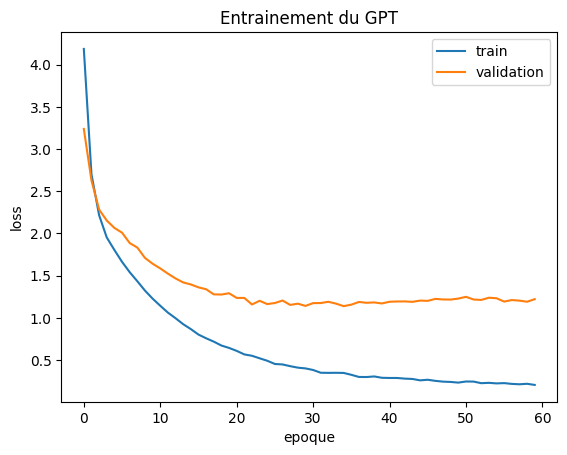

In [10]:
# %% Cellule 8 : entrainement
# [NOUVEAU - points 2,4,6] la loss porte sur  [token categorie] + [4 tokens de l'ID]  :
#   le modele apprend a la fois  "quelle categorie manque ?"  et  "quel article exactement ?".
#   Les infos de contexte (style/saison/couleurs) sont cachees au hasard (META_DROP) pour
#   qu'il marche aussi quand l'utilisateur ne les donne pas.
def make_batch(samples, shuffle=True, meta_drop=0.0):
    seqs = []
    for t, ctx, of in samples:
        c = ctx[:]
        if shuffle:
            random.shuffle(c)
        seqs.append(build_seq(c, meta_tokens(of["meta"], meta_drop), t, CAT[t]))
    T = max(len(s) for s in seqs)
    x = torch.tensor([s + [PAD] * (T - len(s)) for s in seqs])
    y = x.clone()
    for b, s in enumerate(seqs):
        y[b, :len(s) - (L + 1)] = -100; y[b, len(s):] = -100
    return x.to(dev), y.to(dev)

def batch_loss(x, y):
    logits = gpt(x[:, :-1])
    return F.cross_entropy(logits.reshape(-1, V), y[:, 1:].reshape(-1), ignore_index=-100)

@torch.no_grad()
def eval_loss(samples):
    gpt.eval(); tot = n = 0
    for i in range(0, len(samples), 128):
        x, y = make_batch(samples[i:i + 128], shuffle=False)
        tot += batch_loss(x, y).item() * len(x); n += len(x)
    return tot / n

EPOCHS, BS, PATIENCE, META_DROP = 120, 64, 25, 0.3
opt = torch.optim.AdamW(gpt.parameters(), lr=3e-4, weight_decay=0.05)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=3e-5)
hist_tr, hist_val = [], []
best_val, best_state, wait = 1e9, None, 0
for ep in range(EPOCHS):
    gpt.train()
    train_s = make_samples(pool_train, max_hide=2)      # nouveau masquage a chaque epoque
    random.shuffle(train_s); tot = nb = 0
    for i in range(0, len(train_s), BS):
        x, y = make_batch(train_s[i:i + BS], meta_drop=META_DROP)
        loss = batch_loss(x, y)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step()
        tot += loss.item(); nb += 1
    sched.step()
    hist_tr.append(tot / nb); hist_val.append(eval_loss(val_s))
    if hist_val[-1] < best_val:
        best_val, best_state, wait = hist_val[-1], copy.deepcopy(gpt.state_dict()), 0
    else:
        wait += 1
    if ep % 10 == 0 or ep == EPOCHS - 1:
        print(f"epoque {ep + 1:>3}/{EPOCHS}  loss train {hist_tr[-1]:.3f} | loss validation {hist_val[-1]:.3f}")
    if wait >= PATIENCE:
        print(f"arret anticipe a l'epoque {ep + 1} (validation stable depuis {PATIENCE} epoques)"); break
gpt.load_state_dict(best_state)
print(f"meilleur modele : epoque {int(np.argmin(hist_val)) + 1} (loss validation {best_val:.3f})")
plt.plot(hist_tr, label="train"); plt.plot(hist_val, label="validation")
plt.xlabel("epoque"); plt.ylabel("loss"); plt.legend(); plt.title("Entrainement du GPT"); plt.show()

In [11]:
# %% Cellule 9 : generation, regles de coherence, re-ranking
# [NOUVEAU - points 2,3,7]
RULE_PEN, N_CAT, BEAM = 3.0, 3, 40

# ---------- point 3 : regles de coherence d'une tenue (penalite douce, en "nats") ----------
def rule_penalty(ctx):
    present = {CAT[i] for i in ctx}
    pen = {c: 0.0 for c in CAT_LIST}
    for c in present:
        if c != "other":
            pen[c] = RULE_PEN                       # on a deja cette categorie (les accessoires "other" peuvent se cumuler)
    if "dress" in present:
        pen["top"] = pen["bottom"] = RULE_PEN       # robe deja la -> pas de haut/bas
    if present & {"top", "bottom"}:
        pen["dress"] = RULE_PEN                     # haut/bas deja la -> pas de robe
    return pen

# ---------- point 2 : le modele devine ce qui manque ----------
@torch.no_grad()
def cat_ranking(ctx, of, cg, rules=True, meta=True):
    """Categories les plus probables pour l'article manquant : [(categorie, score), ...]."""
    gpt.eval()
    base = build_seq(ctx, meta_tokens(of["meta"], off=not meta))        # se termine par SEP
    lp = F.log_softmax(gpt(torch.tensor([base]).to(dev))[0, -1][CT_IDS], -1).cpu()
    pen = rule_penalty(ctx) if rules else {c: 0.0 for c in CAT_LIST}
    sc = {c: lp[k].item() - pen[c] for k, c in enumerate(CAT_LIST) if c in cg.allowed}
    return sorted(sc.items(), key=lambda kv: -kv[1])

@torch.no_grad()
def beam_items(base, allowed, beam=BEAM):
    """beam search CONTRAINT : le modele ecrit l'ID token par token, mais seulement des tokens
    qui menent a un vrai article du catalogue."""
    beams = [(0.0, [])]
    for _ in range(L):
        x = torch.tensor([base + b[1] for b in beams]).to(dev)
        lp = F.log_softmax(gpt(x)[:, -1], -1).cpu()
        cand = [(s + row[t].item(), pref + [t]) for (s, pref), row in zip(beams, lp)
                for t in allowed.get(tuple(pref), [])]
        if not cand:
            return []
        beams = sorted(cand, key=lambda c: -c[0])[:beam]
    return [(tok2item[tuple(p)], s) for s, p in beams if tuple(p) in tok2item]

@torch.no_grad()
def generate(ctx, of, cg, tcat=None, meta=True):
    """[(article, score, categorie), ...] tries du meilleur au moins bon.
       tcat donne  -> l'utilisateur dit quelle categorie il cherche ("trouve-moi des chaussures")
       tcat = None -> mode AUTO : le modele decide ce qui manque, puis propose des articles."""
    gpt.eval()
    base = build_seq(ctx, meta_tokens(of["meta"], off=not meta))
    if tcat is not None:
        res = [(i, s, tcat) for i, s in beam_items(base + [CT[tcat]], cg.allowed.get(tcat, {}))]
    else:
        res = []
        for c, cs in cat_ranking(ctx, of, cg, meta=meta)[:N_CAT]:
            res += [(i, cs + s, c) for i, s in beam_items(base + [CT[c]], cg.allowed[c])]   # score = log P(cat) + log P(article | cat)
    return sorted([r for r in res if r[0] not in ctx], key=lambda r: -r[1])
@torch.no_grad()
def complete_multi(ctx, of, cg, n_items=2, meta=True):
    """Complète une tenue en devinant n_items (1 ou 2) articles manquants.
    Génération séquentielle : on devine le 1er, on l'ajoute au contexte, puis le 2e.
    Retourne [(item, score, categorie), ...]."""
    gpt.eval()
    results = []
    current_ctx = list(ctx)
    for _ in range(n_items):
        base = build_seq(current_ctx, meta_tokens(of["meta"], off=not meta))
        # Catégorie la plus probable (en tenant compte des règles de cohérence)
        cat_rank = cat_ranking(current_ctx, of, cg, meta=meta)
        if not cat_rank:
            break
        best_cat, cat_score = cat_rank[0]
        # Générer l'item de cette catégorie
        items = beam_items(base + [CT[best_cat]], cg.allowed.get(best_cat, {}))
        if not items:
            break
        best_item, item_score = items[0]
        # Éviter de re-proposer un item déjà présent
        if best_item in current_ctx:
            # fallback : prendre le 2e meilleur
            items = [it for it in items if it[0] not in current_ctx]
            if not items:
                break
            best_item, item_score = items[0]
        results.append((best_item, cat_score + item_score, best_cat))
        current_ctx.append(best_item)
    return results

# ---------- point 7 : compatibilite de couleurs APPRISE sur les tenues du train + re-ranking ----------
NC = len(COLORS)
def pal_vec(names):
    v = np.zeros(NC, dtype=np.float32)
    for p in pal_names(names):
        for j, cn in enumerate(COLORS):
            if cn in p:
                v[j] = 1
    return v
for of in raw_outfits:
    of["pal"] = pal_vec(of["colors"])               # palette officielle de la tenue (si elle contient des couleurs connues)

co = np.full((NC, NC), 0.5)                         # co-occurrence de couleurs entre articles d'une meme tenue
for of in pool_train:
    P = COLP[of["items"]]; S = P.sum(0)
    co += np.outer(S, S) - P.T @ P
co /= co.sum(); marg = co.sum(1)
PMI = np.clip(np.log(co / np.outer(marg, marg)), -2, 2).astype(np.float32)   # >0 : ces couleurs vont bien ensemble
PAL_W = 1.0

def compat_scores(cands, ctx, pal):
    Pc, Px = COLP[cands], COLP[ctx]
    s = (Pc @ PMI @ Px.T).mean(1)                   # compatibilite apprise avec les articles deja dans la tenue
    if pal is not None and pal.sum() > 0:
        s = s + PAL_W * (Pc @ pal) / pal.sum()      # + accord avec la palette demandee
    return s

def rerank(res, ctx, pal, lam, mu, topn=10):
    """score final = score GPT + lam * compat_couleurs ; puis selection MMR : on evite les quasi-doublons (mu)."""
    if not res:
        return []
    items = np.array([r[0] for r in res]); sc = np.array([r[1] for r in res])
    sc = sc + lam * compat_scores(items, ctx, pal)
    sim = emb[items].numpy() @ emb[items].numpy().T
    chosen = []
    while len(chosen) < min(topn, len(items)):
        div = sim[:, chosen].max(1) if chosen else np.zeros(len(items))
        val = sc - mu * div
        val[chosen] = -1e9
        chosen.append(int(val.argmax()))
    return [res[j] for j in chosen]

LAM, MU = 1.0, 0.3                                  # valeurs par defaut, ajustees sur la validation (cellule 10)

def complete_outfit(ctx, style="", season="", colors=(), want=None, cg=None, topn=3, n_items=1):
    """Fonction 'produit' : ctx = indices d'articles deja choisis.
    want = 'shoes', 'bag'... ou None (le modele decide).
    n_items = 1 ou 2 items à deviner."""
    cg = cg or cg_test
    of = dict(meta=meta_ids(style, season, colors), pal=pal_vec(colors))
    if n_items == 1:
        return rerank(generate(ctx, of, cg, want), ctx, of["pal"], LAM, MU, topn)
    else:
        return rerank(complete_multi(ctx, of, cg, n_items), ctx, of["pal"], LAM, MU, topn)

In [14]:
# %% Cellule 10 : reglage du re-ranking (sur la VALIDATION) puis evaluation sur le TEST
# --- 10a : choix de LAM / MU sur la validation (jamais sur le test) ---
val_cache = [(t, ctx, of, generate(ctx, of, cg_val, CAT[t]), generate(ctx, of, cg_val, None)) for t, ctx, of in val_s]

def val_score(lam, mu):
    tot = 0
    for t, ctx, of, rk, ra in val_cache:
        for res in (rk, ra):
            top = [r[0] for r in rerank(res, ctx, of["pal"], lam, mu, 5)]
            tot += int(t in top[:1]) + int(t in top[:5])
    return tot / (4 * len(val_cache))

grid = [(l, m) for l in (0, 0.5, 1, 2, 4) for m in (0, 0.3, 0.6)]
scores = {g: val_score(*g) for g in grid}
LAM, MU = max(grid, key=lambda g: (round(scores[g], 4), -(g[0] + g[1])))
print("validation (moyenne recall@1 et @5, 2 modes) :  sans re-ranking =", f"{scores[(0, 0)]:.3f}",
      "| meilleur =", f"{scores[(LAM, MU)]:.3f}", f"(LAM={LAM}, MU={MU})")
if len(val_s) < 80:
    print("ATTENTION : peu d'exemples de validation, ce reglage est bruite")

# --- 10b : evaluation ---
def pick_distractors(target, outfit_items, cg, rng, n=3):
    same  = [i for i in cg.items if CAT[i] == CAT[target] and i not in outfit_items]
    other = [i for i in cg.items if i not in outfit_items and i not in same]
    rng.shuffle(same); rng.shuffle(other)
    return (same + other)[:n]

@torch.no_grad()
def fitb_correct(ctx, target, distract, of):
    gpt.eval()
    cands = [target] + distract
    mt = meta_tokens(of["meta"])
    x = torch.tensor([build_seq(ctx, mt, c, CAT[c]) for c in cands]).to(dev)
    lp = F.log_softmax(gpt(x[:, :-1]), -1)
    score = lp.gather(2, x[:, 1:].unsqueeze(-1)).squeeze(-1)[:, -(L + 1):].sum(1)
    return int(score.argmax().item() == 0)

def evaluate_all(samples, cg, ks=(1, 5, 10)):
    rng = random.Random(7)
    R = defaultdict(lambda: defaultdict(float))
    cat = defaultdict(float); fitb = viol = 0
    for t, ctx, of in samples:
        sims = emb @ F.normalize(emb[ctx].mean(0), dim=0)
        pools = {"known": [i for i in cg.by_cat[CAT[t]] if i not in ctx],
                 "auto":  [i for i in cg.items if i not in ctx]}
        def clip_rank(p):
            return [p[j] for j in sims[p].argsort(descending=True).tolist()]
        ranked = {
            "known": {"GPT": generate(ctx, of, cg, CAT[t]),
                      "GPT sans meta": generate(ctx, of, cg, CAT[t], meta=False)},
            "auto":  {"GPT": generate(ctx, of, cg, None)},
        }
        for mode in ("known", "auto"):
            for k in ks:
                R[("Hasard", mode)][k] += min(k, len(pools[mode])) / max(len(pools[mode]), 1)
            for name, res in ranked[mode].items():
                for k in ks:
                    R[(name, mode)][k] += int(t in [r[0] for r in res][:k])
            top = [r[0] for r in rerank(ranked[mode]["GPT"], ctx, of["pal"], LAM, MU, max(ks))]
            for k in ks:
                R[("GPT + rerank", mode)][k] += int(t in top[:k])
                R[("CLIP (article proche)", mode)][k] += int(t in clip_rank(pools[mode])[:k])
        rk  = [c for c, _ in cat_ranking(ctx, of, cg)]
        rk0 = [c for c, _ in cat_ranking(ctx, of, cg, rules=False)]
        cat["top1"] += rk[0] == CAT[t];  cat["top3"] += CAT[t] in rk[:3]
        cat["top1_sans_regles"] += rk0[0] == CAT[t]; cat["top3_sans_regles"] += CAT[t] in rk0[:3]
        viol += rule_penalty(ctx)[CAT[t]] > 0
        fitb += fitb_correct(ctx, t, pick_distractors(t, ctx + [t], cg, rng), of)
    n = len(samples)
    return ({k: {kk: vv / n for kk, vv in v.items()} for k, v in R.items()},
            {k: v / n for k, v in cat.items()}, fitb / n, viol / n)


# [NOUVEAU] Évaluation de la complétion de 1 ou 2 items dans une tenue partielle
def evaluate_completion(samples, cg, n_items=2):
    """Pour chaque tenue : on cache n_items items, on laisse le reste en contexte,
    et on mesure combien de cibles le modèle retrouve dans ses prédictions.
    Retourne (precision@1, precision@n_items)."""
    rng = random.Random(42)
    hits1 = hits_all = total = 0
    for t, ctx, of in samples:
        its = of["items"]
        if len(its) < n_items + 1:          # besoin d'au moins n_items cibles + 1 contexte
            continue
        others = [i for i in its if i != t]
        if len(others) < n_items - 1:
            continue
        targets   = [t] + rng.sample(others, n_items - 1)
        remaining = [i for i in its if i not in targets]
        if len(remaining) < 1:
            continue

        pred = complete_multi(remaining, of, cg, n_items=n_items)
        pred_items = [p[0] for p in pred]

        # precision@1 : la 1re prédiction est-elle l'une des cibles ?
        if pred_items and pred_items[0] in targets:
            hits1 += 1
        # precision@n_items : combien de cibles apparaissent dans les n_items prédictions
        hits_all += sum(1 for tg in targets if tg in pred_items[:n_items])
        total += len(targets)

    return (hits1 / max(len(samples), 1),
            hits_all / total if total else 0.0)


if len(test_s) > 0:
    acc1, acc_all = evaluate_completion(test_s, cg_test, n_items=2)
    print(f"\n[NOUVEAU] Complétion de 2 items cachés : precision@1 = {acc1:.2f} | precision@2 = {acc_all:.2f}")

R, CATR, FITB, VIOL = evaluate_all(test_s, cg_test)
print(f"\n=== TEST : {len(test_s)} cas, {len(pool_test)} tenues jamais vues, catalogue de {len(cg_test.items)} articles ===")
for mode, title in (("known", "MODE 1 - l'utilisateur dit quelle categorie il cherche (candidats : cette categorie)"),
                    ("auto",  "MODE 2 - le modele decide seul ce qui manque (candidats : tout le catalogue)")):
    print(f"\n{title}\n{'':<26}{'Recall@1':>10}{'Recall@5':>10}{'Recall@10':>10}")
    for name in ("Hasard", "CLIP (article proche)", "GPT sans meta", "GPT", "GPT + rerank"):
        if (name, mode) in R:
            r = R[(name, mode)]
            print(f"{name:<26}{r[1]:>10.3f}{r[5]:>10.3f}{r[10]:>10.3f}")
print(f"\nCategorie manquante bien devinee : top-1 {CATR['top1']:.2f} | top-3 {CATR['top3']:.2f}"
      f"   (sans regles : {CATR['top1_sans_regles']:.2f} | {CATR['top3_sans_regles']:.2f})")
print(f"Regles de coherence : {VIOL:.0%} des vraies cibles vont CONTRE une regle (doit rester faible, sinon assouplir RULE_PEN)")
print(f"FITB (1 vrai parmi 4, memes categories) : {FITB:.2f}   (hasard : 0.25)")

validation (moyenne recall@1 et @5, 2 modes) :  sans re-ranking = 0.667 | meilleur = 0.694 (LAM=2, MU=0)

[NOUVEAU] Complétion de 2 items cachés : precision@1 = 0.37 | precision@2 = 0.35

=== TEST : 310 cas, 92 tenues jamais vues, catalogue de 259 articles ===

MODE 1 - l'utilisateur dit quelle categorie il cherche (candidats : cette categorie)
                            Recall@1  Recall@5 Recall@10
Hasard                         0.028     0.140     0.276
CLIP (article proche)          0.271     0.558     0.742
GPT sans meta                  0.474     0.642     0.713
GPT                            0.516     0.645     0.726
GPT + rerank                   0.532     0.671     0.742

MODE 2 - le modele decide seul ce qui manque (candidats : tout le catalogue)
                            Recall@1  Recall@5 Recall@10
Hasard                         0.004     0.019     0.039
CLIP (article proche)          0.023     0.135     0.213
GPT                            0.319     0.523     0.539
GPT +

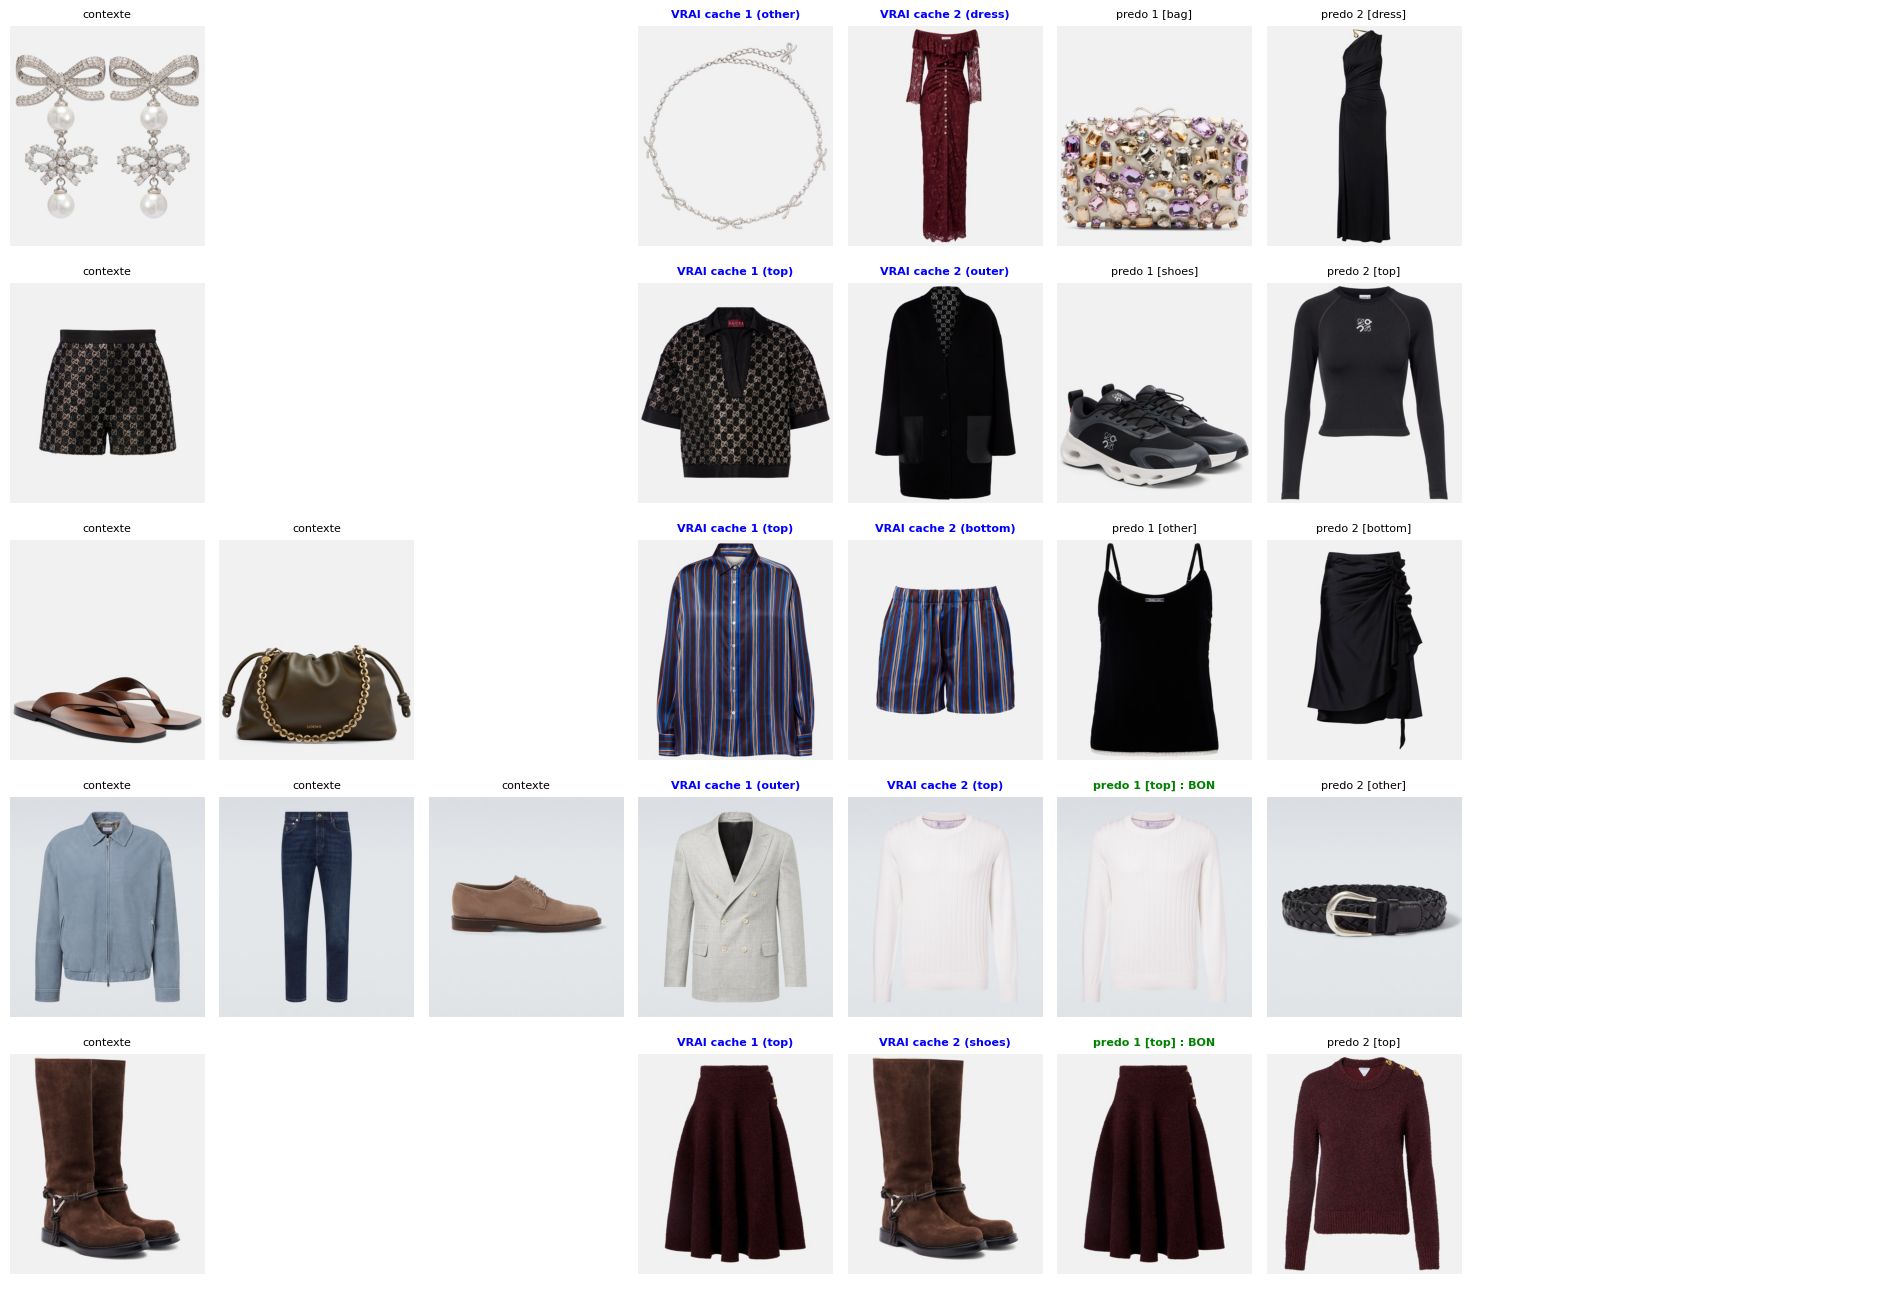

In [15]:
# %% Cellule 11 : RESULTAT EN PHOTOS (mode AUTO + re-ranking, 2 items devinés)
# Pour des tenues de test jamais vues : on cache 2 items, on affiche le contexte,
# les vrais items cachés, et les 2 items proposés par le modèle.
random.seed(5)
show_s = random.sample(test_s, min(5, len(test_s)))

fig, axs = plt.subplots(len(show_s), 9, figsize=(19, 2.6 * len(show_s)), squeeze=False)

for r, (t, ctx, of) in enumerate(show_s):
    for ax in axs[r]:
        ax.axis("off")

    # Choisir un 2e item à cacher (autre que t)
    others = [i for i in of["items"] if i != t]
    second = random.choice(others) if others else None
    targets = [t] + ([second] if second else [])
    remaining = [i for i in ctx if i not in targets]
    if len(remaining) < 1:
        remaining = ctx[:2]

    # Contexte
    for c, it in enumerate(remaining[:3]):
        axs[r][c].imshow(Image.open(f"{OUT}/{used[it]}.jpg"))
        axs[r][c].set_title("contexte", fontsize=8)

    # Vrais items cachés
    for k, tg in enumerate(targets):
        axs[r][3 + k].imshow(Image.open(f"{OUT}/{used[tg]}.jpg"))
        axs[r][3 + k].set_title(f"VRAI cache {k+1} ({CAT[tg]})",
                                fontsize=8, color="blue", weight="bold")

    # Prédictions du modèle (2 items)
    preds = complete_multi(remaining, of, cg_test, n_items=len(targets))
    for k, (p, _, c) in enumerate(preds[:2]):
        axs[r][5 + k].imshow(Image.open(f"{OUT}/{used[p]}.jpg"))
        good = p in targets
        axs[r][5 + k].set_title(f"predo {k+1} [{c}]" + (" : BON" if good else ""),
                                fontsize=8,
                                color="green" if good else "black",
                                weight="bold" if good else "normal")

plt.tight_layout()
plt.show()

# Exemple d'utilisation "produit" : deviner 2 items dans une tenue partielle
# t, ctx, of = test_s[0]
# complete_outfit(ctx, style="evening", season="winter", colors=["black"], n_items=2)


--- 2 articles caches | 310 cas | 92 tenues de test ---
                         retrouves top-5 retrouves top-10   TOUS top-10
Hasard                             0.019            0.039         0.001
CLIP (article proche)              0.111            0.173         0.045
GPT + rerank                       0.495            0.568         0.403

--- 3 articles caches | 118 cas | 28 tenues de test ---
                         retrouves top-5 retrouves top-10   TOUS top-10
Hasard                             0.019            0.039         0.000
CLIP (article proche)              0.054            0.130         0.000
GPT + rerank                       0.314            0.412         0.102


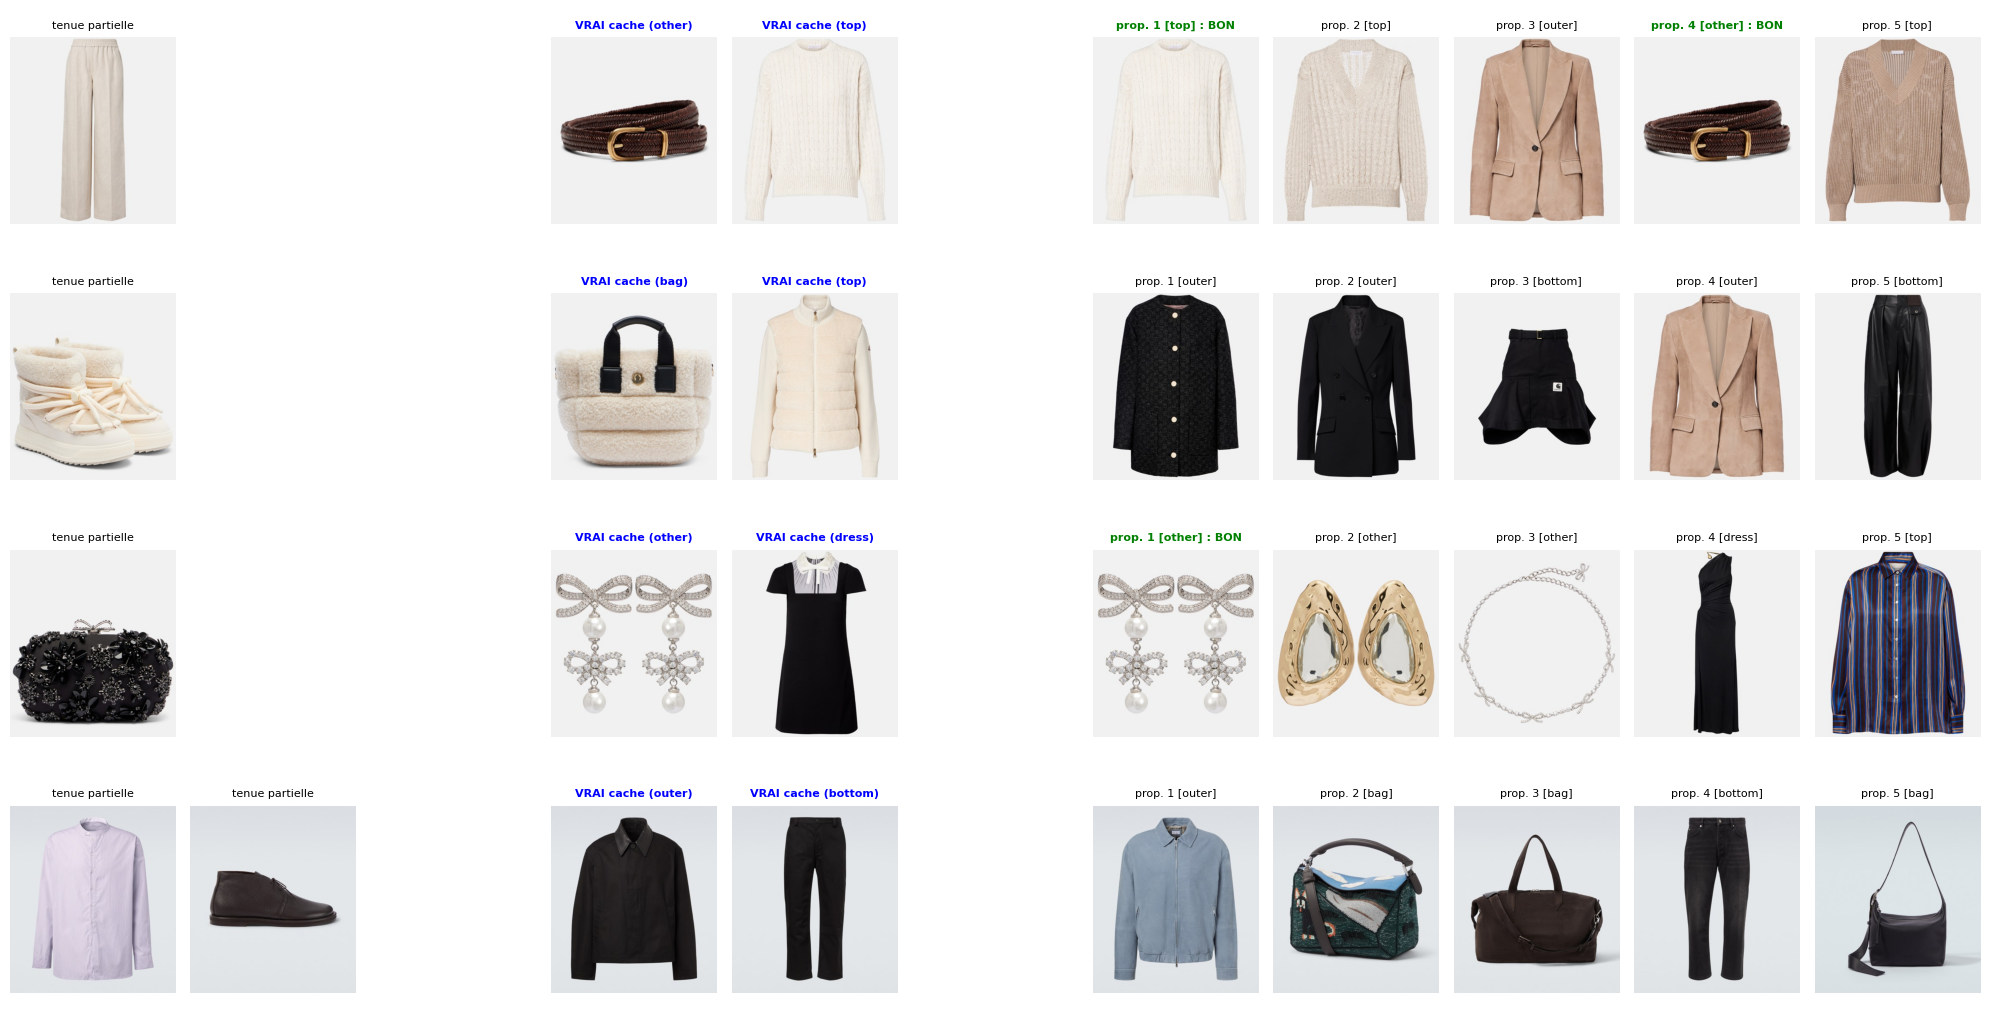

In [16]:
# %% Cellule 12 : [NOUVEAU] test avec PLUSIEURS articles manquants (2, puis 3)
# Jusqu'ici le test cachait toujours 1 seul article. Ici on cache h articles de la meme tenue :
# le modele recoit la tenue partielle (en mode AUTO, sans qu'on lui dise ce qui manque) et propose
# 10 articles ; on regarde combien des articles caches il retrouve.
import math

def make_multi_samples(pool, h, seed=11):
    rng = random.Random(seed); out = []
    for of in pool:
        its = of["items"]
        if len(its) - h < 1:                       # il doit rester au moins 1 article de contexte
            continue
        for _ in range(len(its)):                  # quelques tirages differents par tenue
            hidden = rng.sample(its, h)
            out.append((hidden, [i for i in its if i not in hidden], of))
    return out

def eval_multi(h, ks=(5, 10)):
    ms = make_multi_samples(pool_test, h)
    if not ms:
        print(f"h={h} : pas assez d'articles par tenue"); return None
    A = defaultdict(float)
    for hidden, ctx, of in ms:
        top = [r[0] for r in rerank(generate(ctx, of, cg_test), ctx, of["pal"], LAM, MU, max(ks))]
        sims = emb @ F.normalize(emb[ctx].mean(0), dim=0)
        pool = [i for i in cg_test.items if i not in ctx]
        clip_top = [pool[j] for j in sims[pool].argsort(descending=True).tolist()]
        n = len(pool)
        for k in ks:
            A[("Hasard", k)] += min(k, n) / n
            A[("CLIP (article proche)", k)] += np.mean([t in clip_top[:k] for t in hidden])
            A[("GPT + rerank", k)] += np.mean([t in top[:k] for t in hidden])
        k = max(ks)
        A[("Hasard", "tous")] += math.comb(n - h, k - h) / math.comb(n, k) if n >= k >= h else 0
        A[("CLIP (article proche)", "tous")] += all(t in clip_top[:k] for t in hidden)
        A[("GPT + rerank", "tous")] += all(t in top[:k] for t in hidden)
    print(f"\n--- {h} articles caches | {len(ms)} cas | {len({id(of) for _, _, of in ms})} tenues de test ---")
    print(f"{'':<24}{'retrouves top-' + str(ks[0]):>16}{'retrouves top-' + str(ks[1]):>17}{'TOUS top-' + str(ks[1]):>14}")
    for name in ("Hasard", "CLIP (article proche)", "GPT + rerank"):
        print(f"{name:<24}{A[(name, ks[0])] / len(ms):>16.3f}{A[(name, ks[1])] / len(ms):>17.3f}{A[(name, 'tous')] / len(ms):>14.3f}")
    return ms

multi = {h: eval_multi(h) for h in (2, 3)}

# ---- photos : tenue partielle | articles caches | 5 propositions (vert = un des articles caches) ----
ms2 = multi.get(2)
if ms2:
    random.seed(3)
    show = random.sample(ms2, min(4, len(ms2)))
    fig, axs = plt.subplots(len(show), 11, figsize=(20, 2.6 * len(show)), squeeze=False)
    for r, (hidden, ctx, of) in enumerate(show):
        for ax in axs[r]:
            ax.axis("off")
        for c, it in enumerate(ctx[:3]):
            axs[r][c].imshow(Image.open(f"{OUT}/{used[it]}.jpg")); axs[r][c].set_title("tenue partielle", fontsize=8)
        for c, it in enumerate(hidden):
            axs[r][3 + c].imshow(Image.open(f"{OUT}/{used[it]}.jpg"))
            axs[r][3 + c].set_title(f"VRAI cache ({CAT[it]})", fontsize=8, color="blue", weight="bold")
        for k, (p, _, c) in enumerate(rerank(generate(ctx, of, cg_test), ctx, of["pal"], LAM, MU, 5)):
            axs[r][6 + k].imshow(Image.open(f"{OUT}/{used[p]}.jpg"))
            good = p in hidden
            axs[r][6 + k].set_title(f"prop. {k + 1} [{c}]" + (" : BON" if good else ""), fontsize=8,
                                    color="green" if good else "black", weight="bold" if good else "normal")
    plt.tight_layout(); plt.show()

In [17]:
full = Counter(len(o["outfit"]) for o in data.values()
               if o["is_official_outfit"] and o["is_official_look"])
kept = Counter(len(of["codes"]) for of in raw_outfits)
print("taille des tenues, dataset complet :", sorted(full.items()))
print("taille des tenues, gardees (avec photo) :", sorted(kept.items()))

taille des tenues, dataset complet : [(1, 282), (2, 3024), (3, 11713), (4, 11107), (5, 8770), (6, 3746), (7, 1403), (8, 144), (9, 30), (10, 3)]
taille des tenues, gardees (avec photo) : [(3, 333), (4, 102), (5, 21)]


In [18]:
shrink = Counter()
for oid, o in data.items():
    if o["is_official_outfit"] and o["is_official_look"]:
        codes = [c for c in o["outfit"] if c in avail]
        if len(codes) >= 3:
            shrink[(len(o["outfit"]), len(codes))] += 1      # (taille reelle, taille gardee)
print(sorted(shrink.items()))

[((3, 3), 62), ((4, 3), 97), ((4, 4), 21), ((5, 3), 99), ((5, 4), 32), ((5, 5), 11), ((6, 3), 46), ((6, 4), 37), ((6, 5), 4), ((7, 3), 20), ((7, 4), 10), ((7, 5), 6), ((7, 6), 7), ((8, 3), 5), ((8, 4), 2), ((8, 6), 1), ((8, 7), 2), ((9, 3), 4), ((9, 7), 1)]
